In [4]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")


from trips.test_problems.Tomography import Tomography
from trips.utilities.io import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *

import astra

import jlinops


from rsolvers import RIASGKS, RMMGKS

# Start problem

In [5]:
(F , d , Aseq , B , nx , ny , nt ) = generate_emoji( dataset = 30)

data already downloaded.


# RMMGKS

In [33]:
time_step = 5
A1 = Aseq[time_step]
b1 = B[time_step]
#L = gen_first_derivative_operator_2D(nx, ny)
L = jlinops.Neumann2D((nx,ny))
data_vec = d.reshape((-1,1))
delta = 0.2

# Use RMMGKS to compute an approximate solution
rmmgks_solver = RMMGKS(A1, L, b1.flatten(), noise_var=delta**2)
data = rmmgks_solver.solve(n_iter=1000, init_dim=5, kmin=5, kmax=25, q=1.0, epsilon=1e-3, x_true=None, regparam="dp3", eta=1.01)

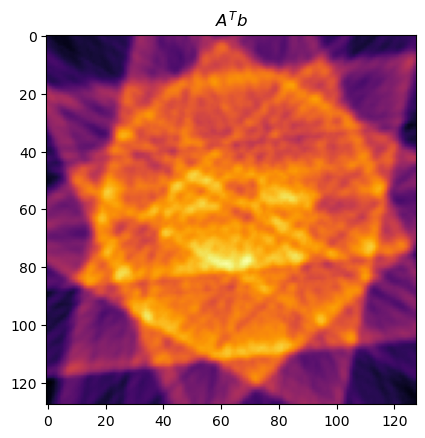

In [49]:
plt.imshow((A1.T @ b1).reshape((nx,ny)))
plt.title("$A^T b$")
plt.set_cmap('inferno')
plt.show()

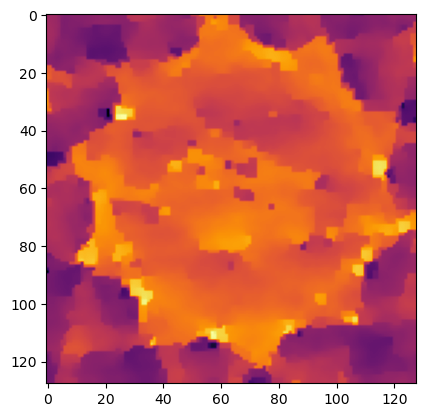

In [34]:
plt.imshow(data["x"].reshape((nx,ny)))
plt.set_cmap('inferno')
plt.show()

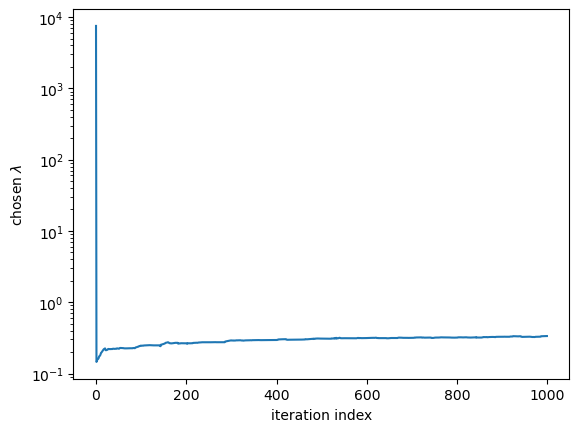

In [35]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

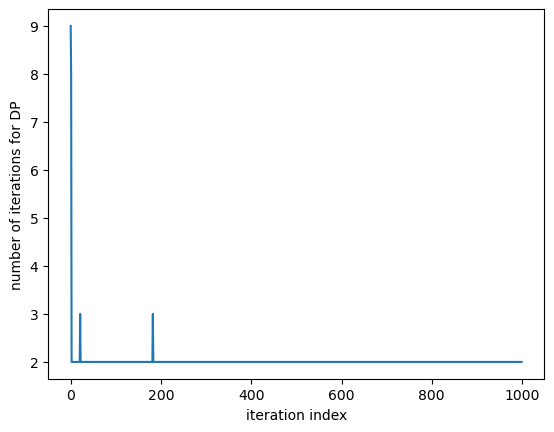

In [36]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

IndexError: index 5 is out of bounds for axis 1 with size 5

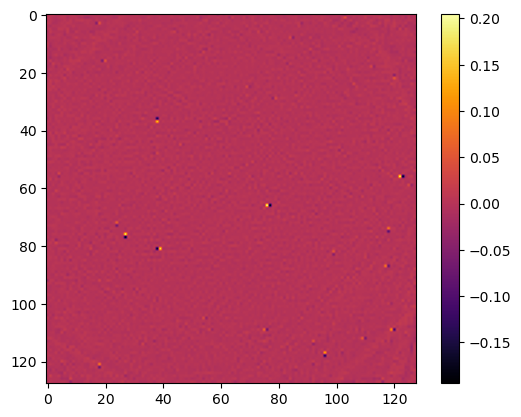

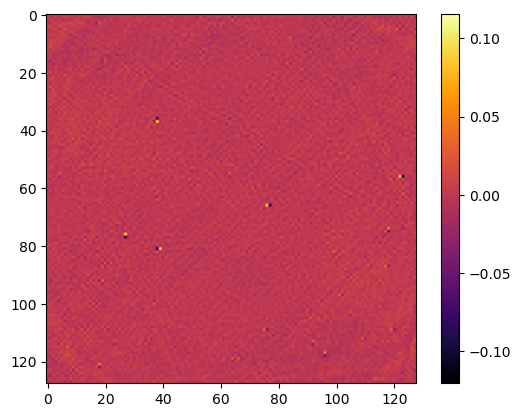

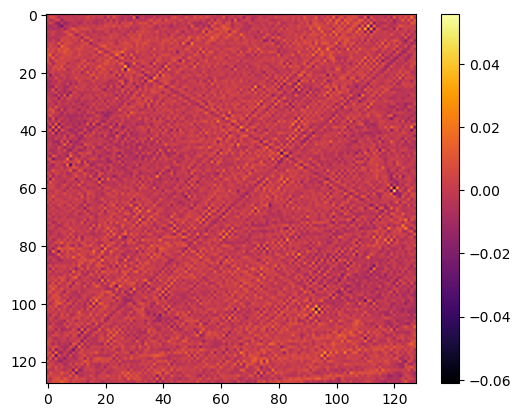

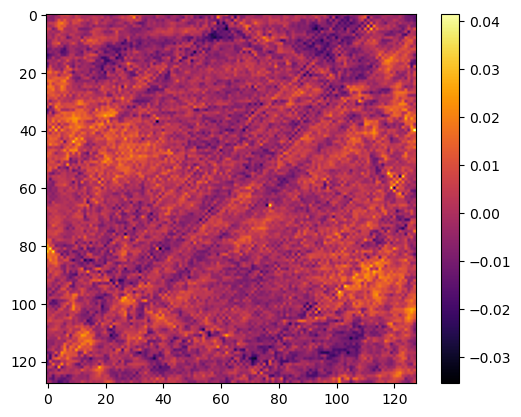

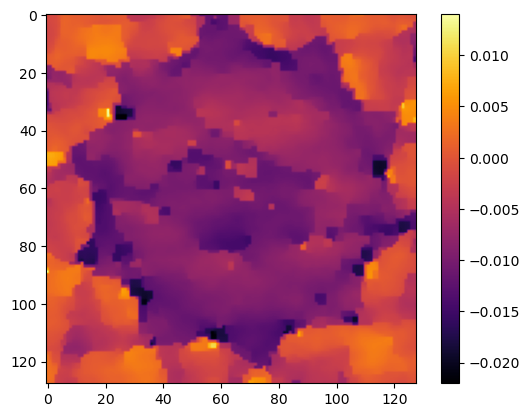

In [37]:
for j in range(10):
    tmp = data["V"][:,j].reshape((nx,ny))
    plt.figure()
    plt.imshow(tmp)
    plt.colorbar()

# IASGKS

In [40]:
# Use RMMGKS to compute an approximate solution
rmmgks_solver = RIASGKS(A1, L, b1.flatten(), noise_var=delta**2)
data = rmmgks_solver.solve(n_iter=1000, init_dim=5, kmin=5, kmax=25, hyperpr_r=-1, hyperpr_beta=1.0, x_true=None, regparam="dp3", eta=1.01)

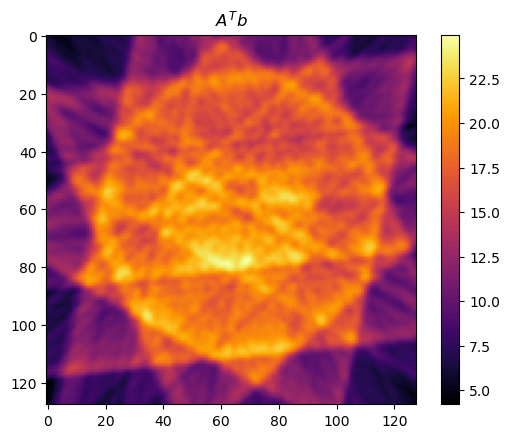

In [56]:
plt.imshow((A1.T @ b1).reshape((nx,ny)))
plt.title("$A^T b$")
plt.set_cmap('inferno')
plt.colorbar()
plt.show()

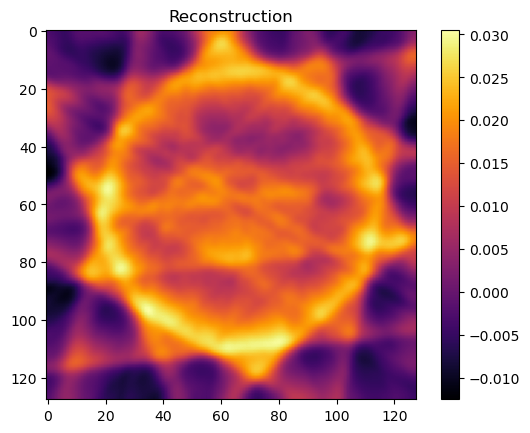

In [57]:
plt.imshow(data["x"].reshape((nx,ny)))
plt.title("Reconstruction")
plt.set_cmap('inferno')
plt.colorbar()
plt.show()

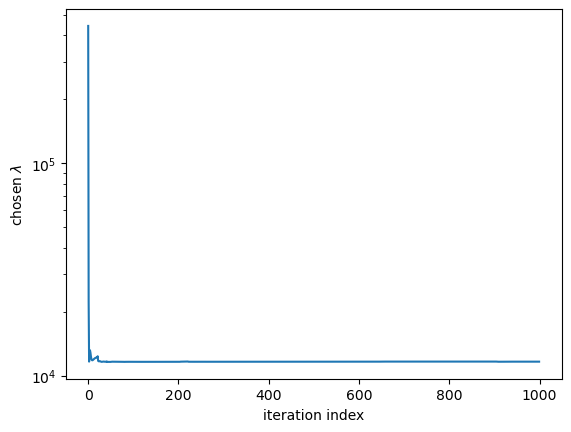

In [58]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

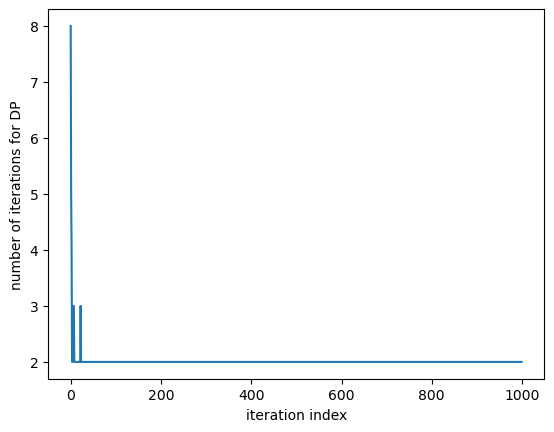

In [59]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

IndexError: index 5 is out of bounds for axis 1 with size 5

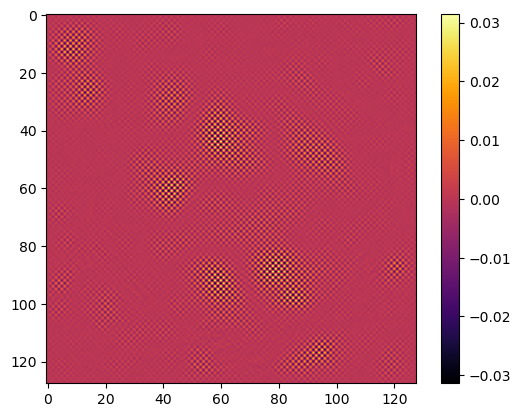

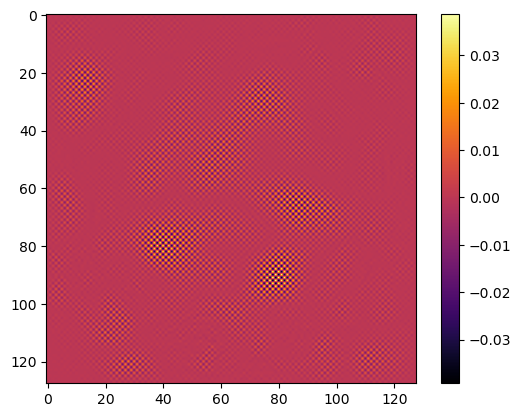

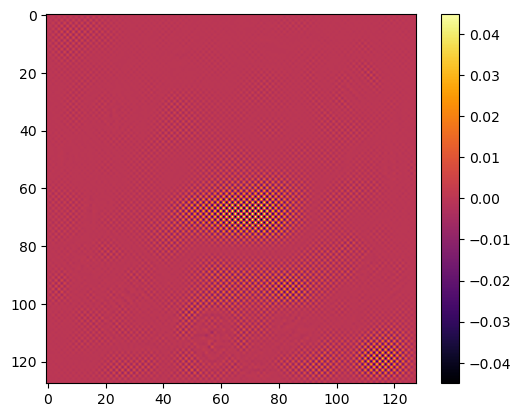

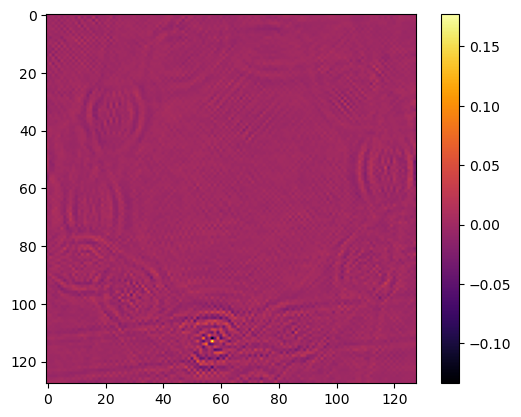

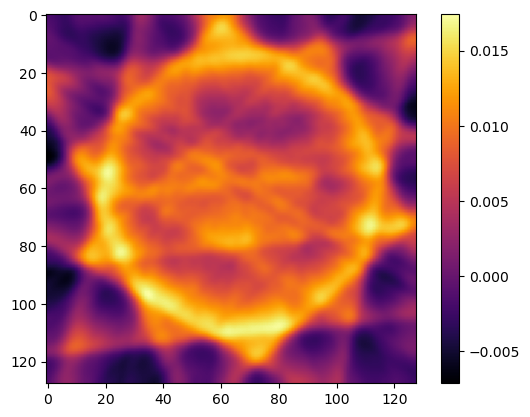

In [60]:
for j in range(10):
    tmp = data["V"][:,j].reshape((nx,ny))
    plt.figure()
    plt.imshow(tmp)
    plt.colorbar()

# Solve large problem?

In [65]:
# Use RMMGKS to compute an approximate solution
nt = 33
L = gen_spacetime_derivative_operator(nx, ny, nt)
rmmgks_solver = RIASGKS(F, L, data_vec.flatten(), noise_var=delta**2)
data = rmmgks_solver.solve(n_iter=1000, init_dim=5, kmin=5, kmax=25, hyperpr_r=-1, hyperpr_beta=1.0, x_true=None, regparam="dp3", eta=1.01)

<Figure size 640x480 with 0 Axes>

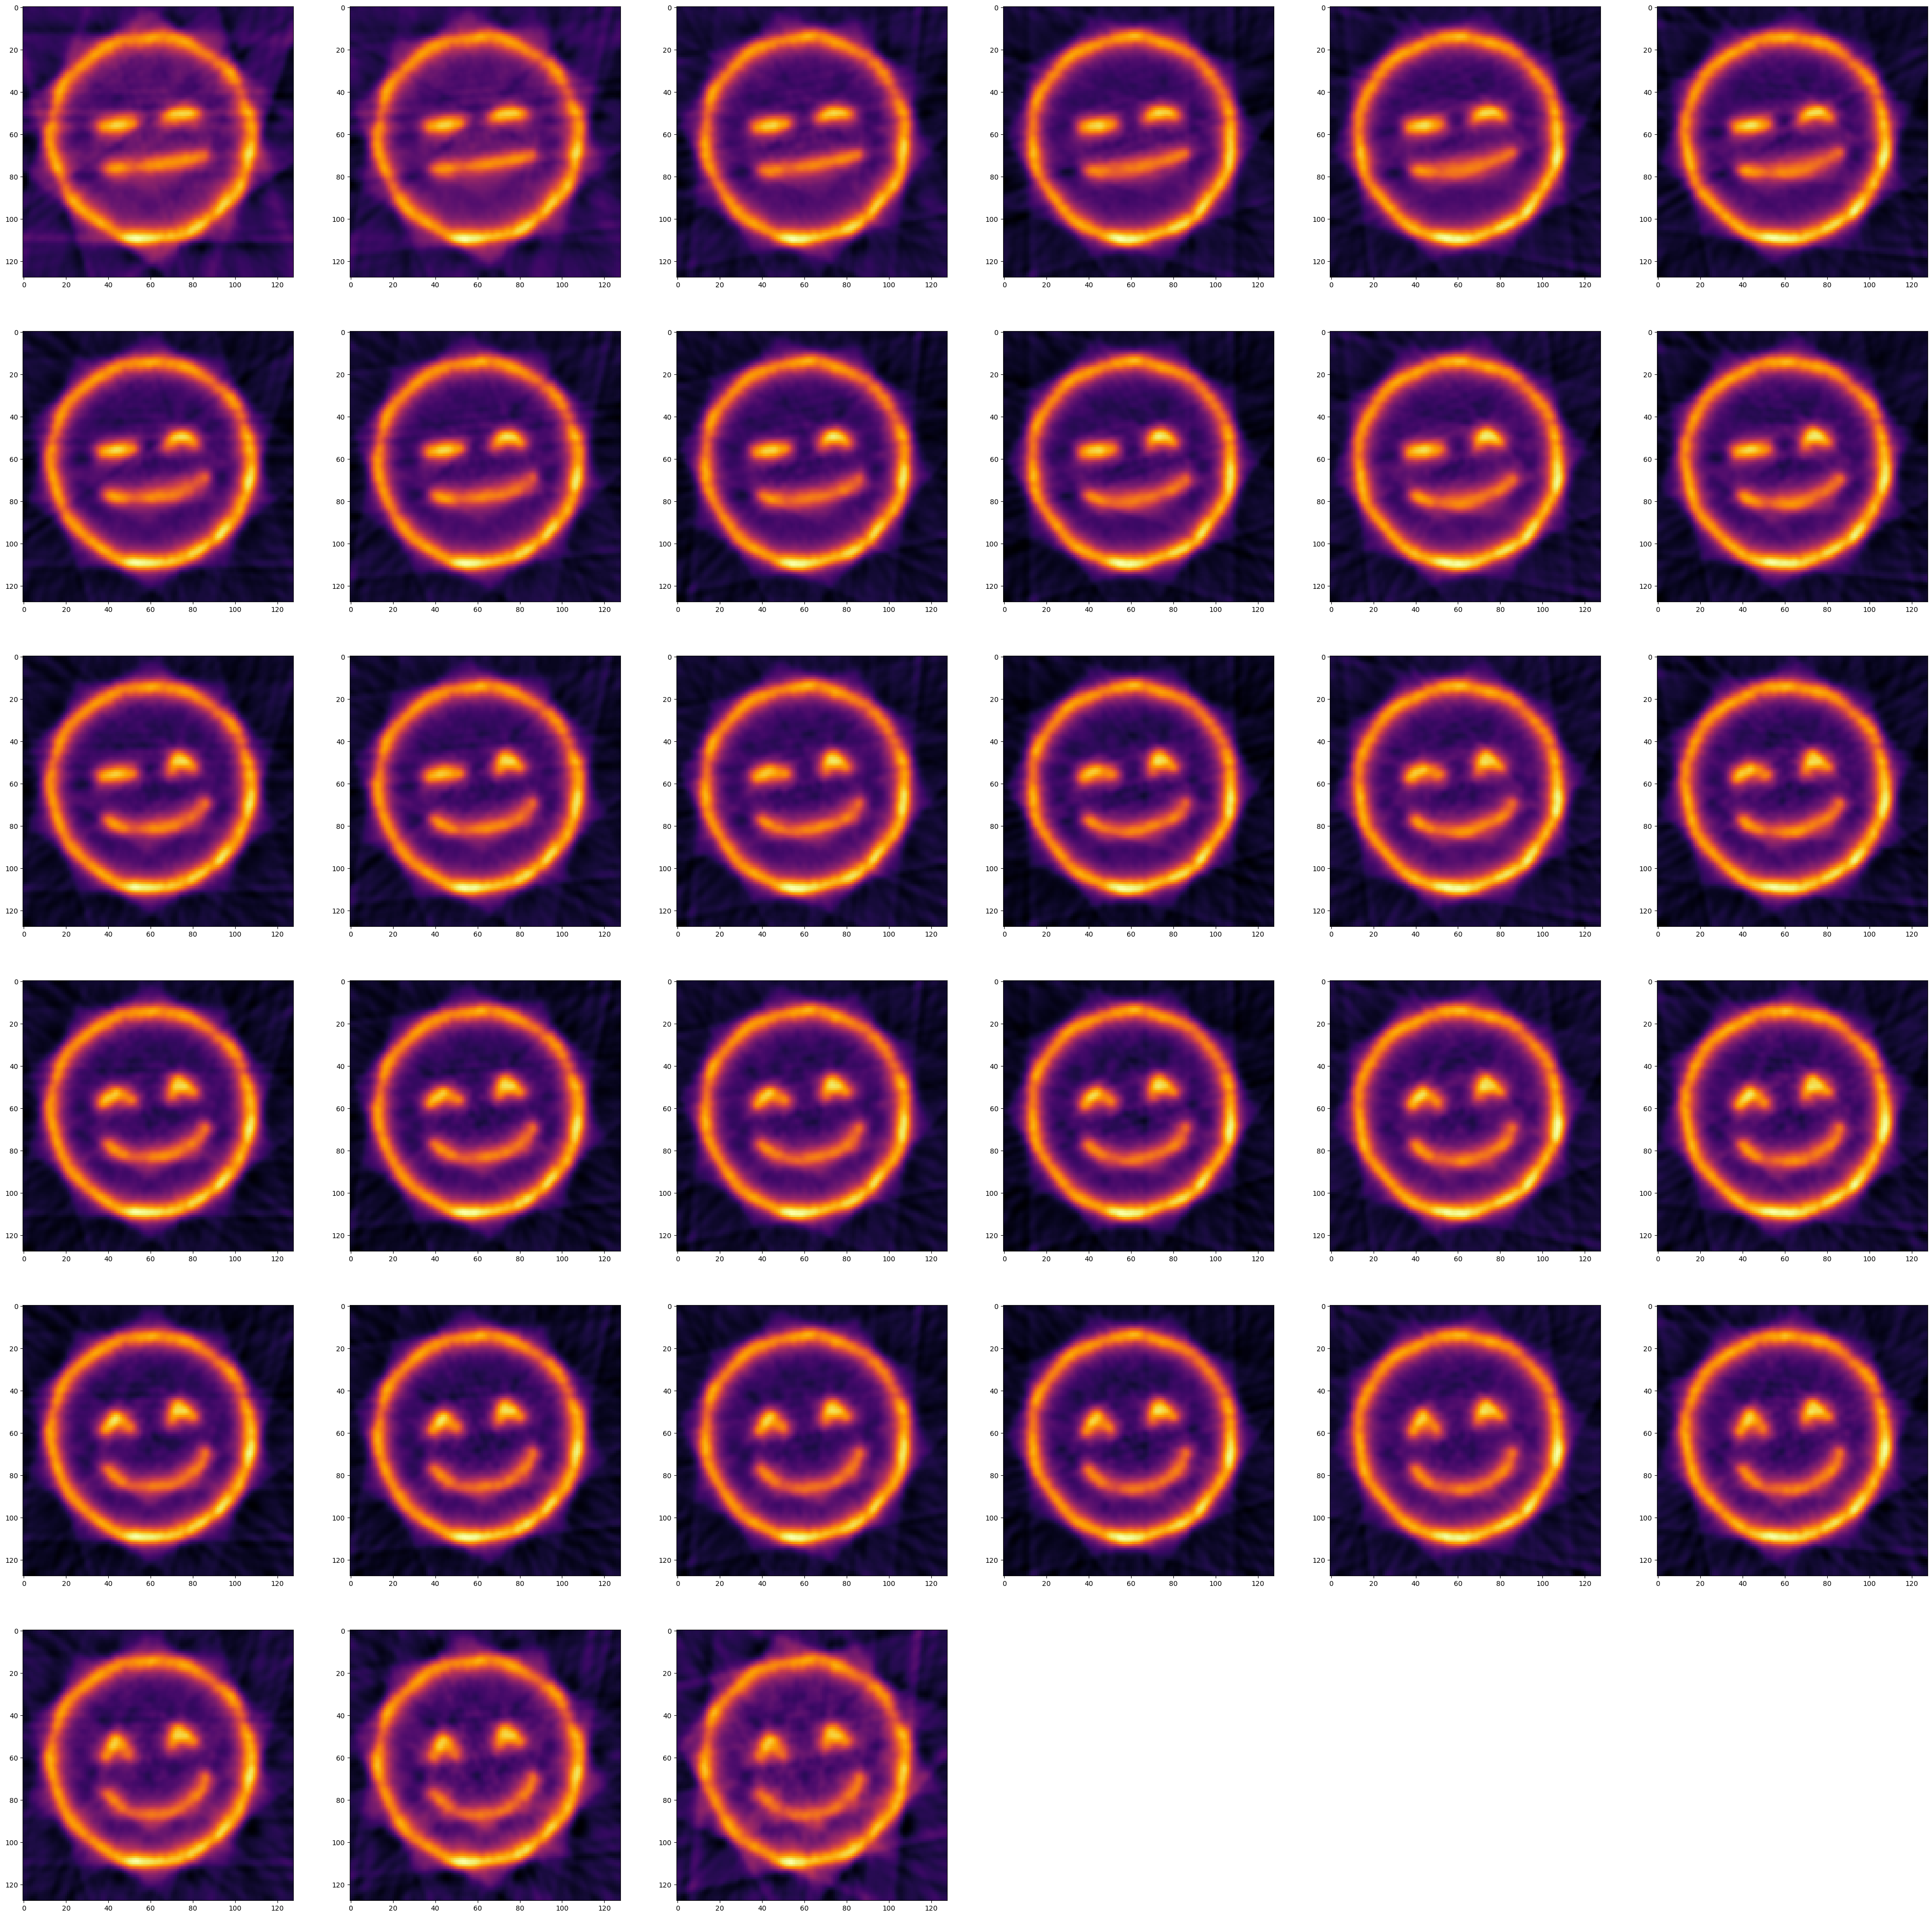

In [66]:
plot_recstructions_series(data["x"], (nx, ny, nt), dynamic = True, testproblem = 'Emoji', geome_x = 1,geome_x_small = 0,  save_imgs= False, save_path='./reconstruction/Emoji')

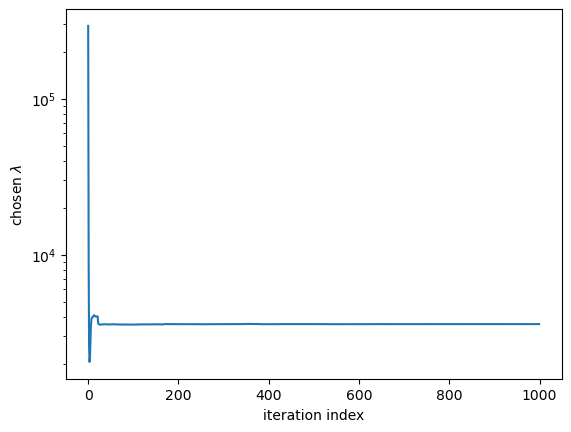

In [67]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

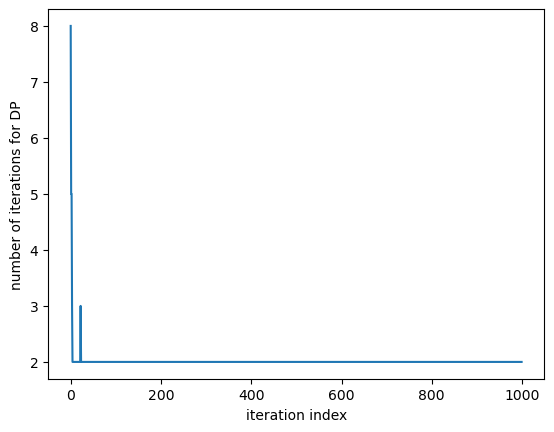

In [68]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

In [2]:
from trips.solvers import GKS

In [7]:
# Define the regularization operator
# L = spatial_derivative_operator(nx, ny, nt)
nt = 33
L = gen_spacetime_derivative_operator(nx, ny, nt)
data_vec = d.reshape((-1,1))
# Use GKS to compute an approximate solution
(x_TV_iso, info_TV_iso) = GKS(F, data_vec, L, projection_dim=1, n_iter = 30, regparam = 'gcv', x_true = None, isoTV = 'isoTV', prob_dims = (nx, ny, nt))

generating basis...:   0%|          | 0/1 [00:00<?, ?it/s]

running GKS...: 100%|██████████| 30/30 [01:34<00:00,  3.16s/it]


<Figure size 640x480 with 0 Axes>

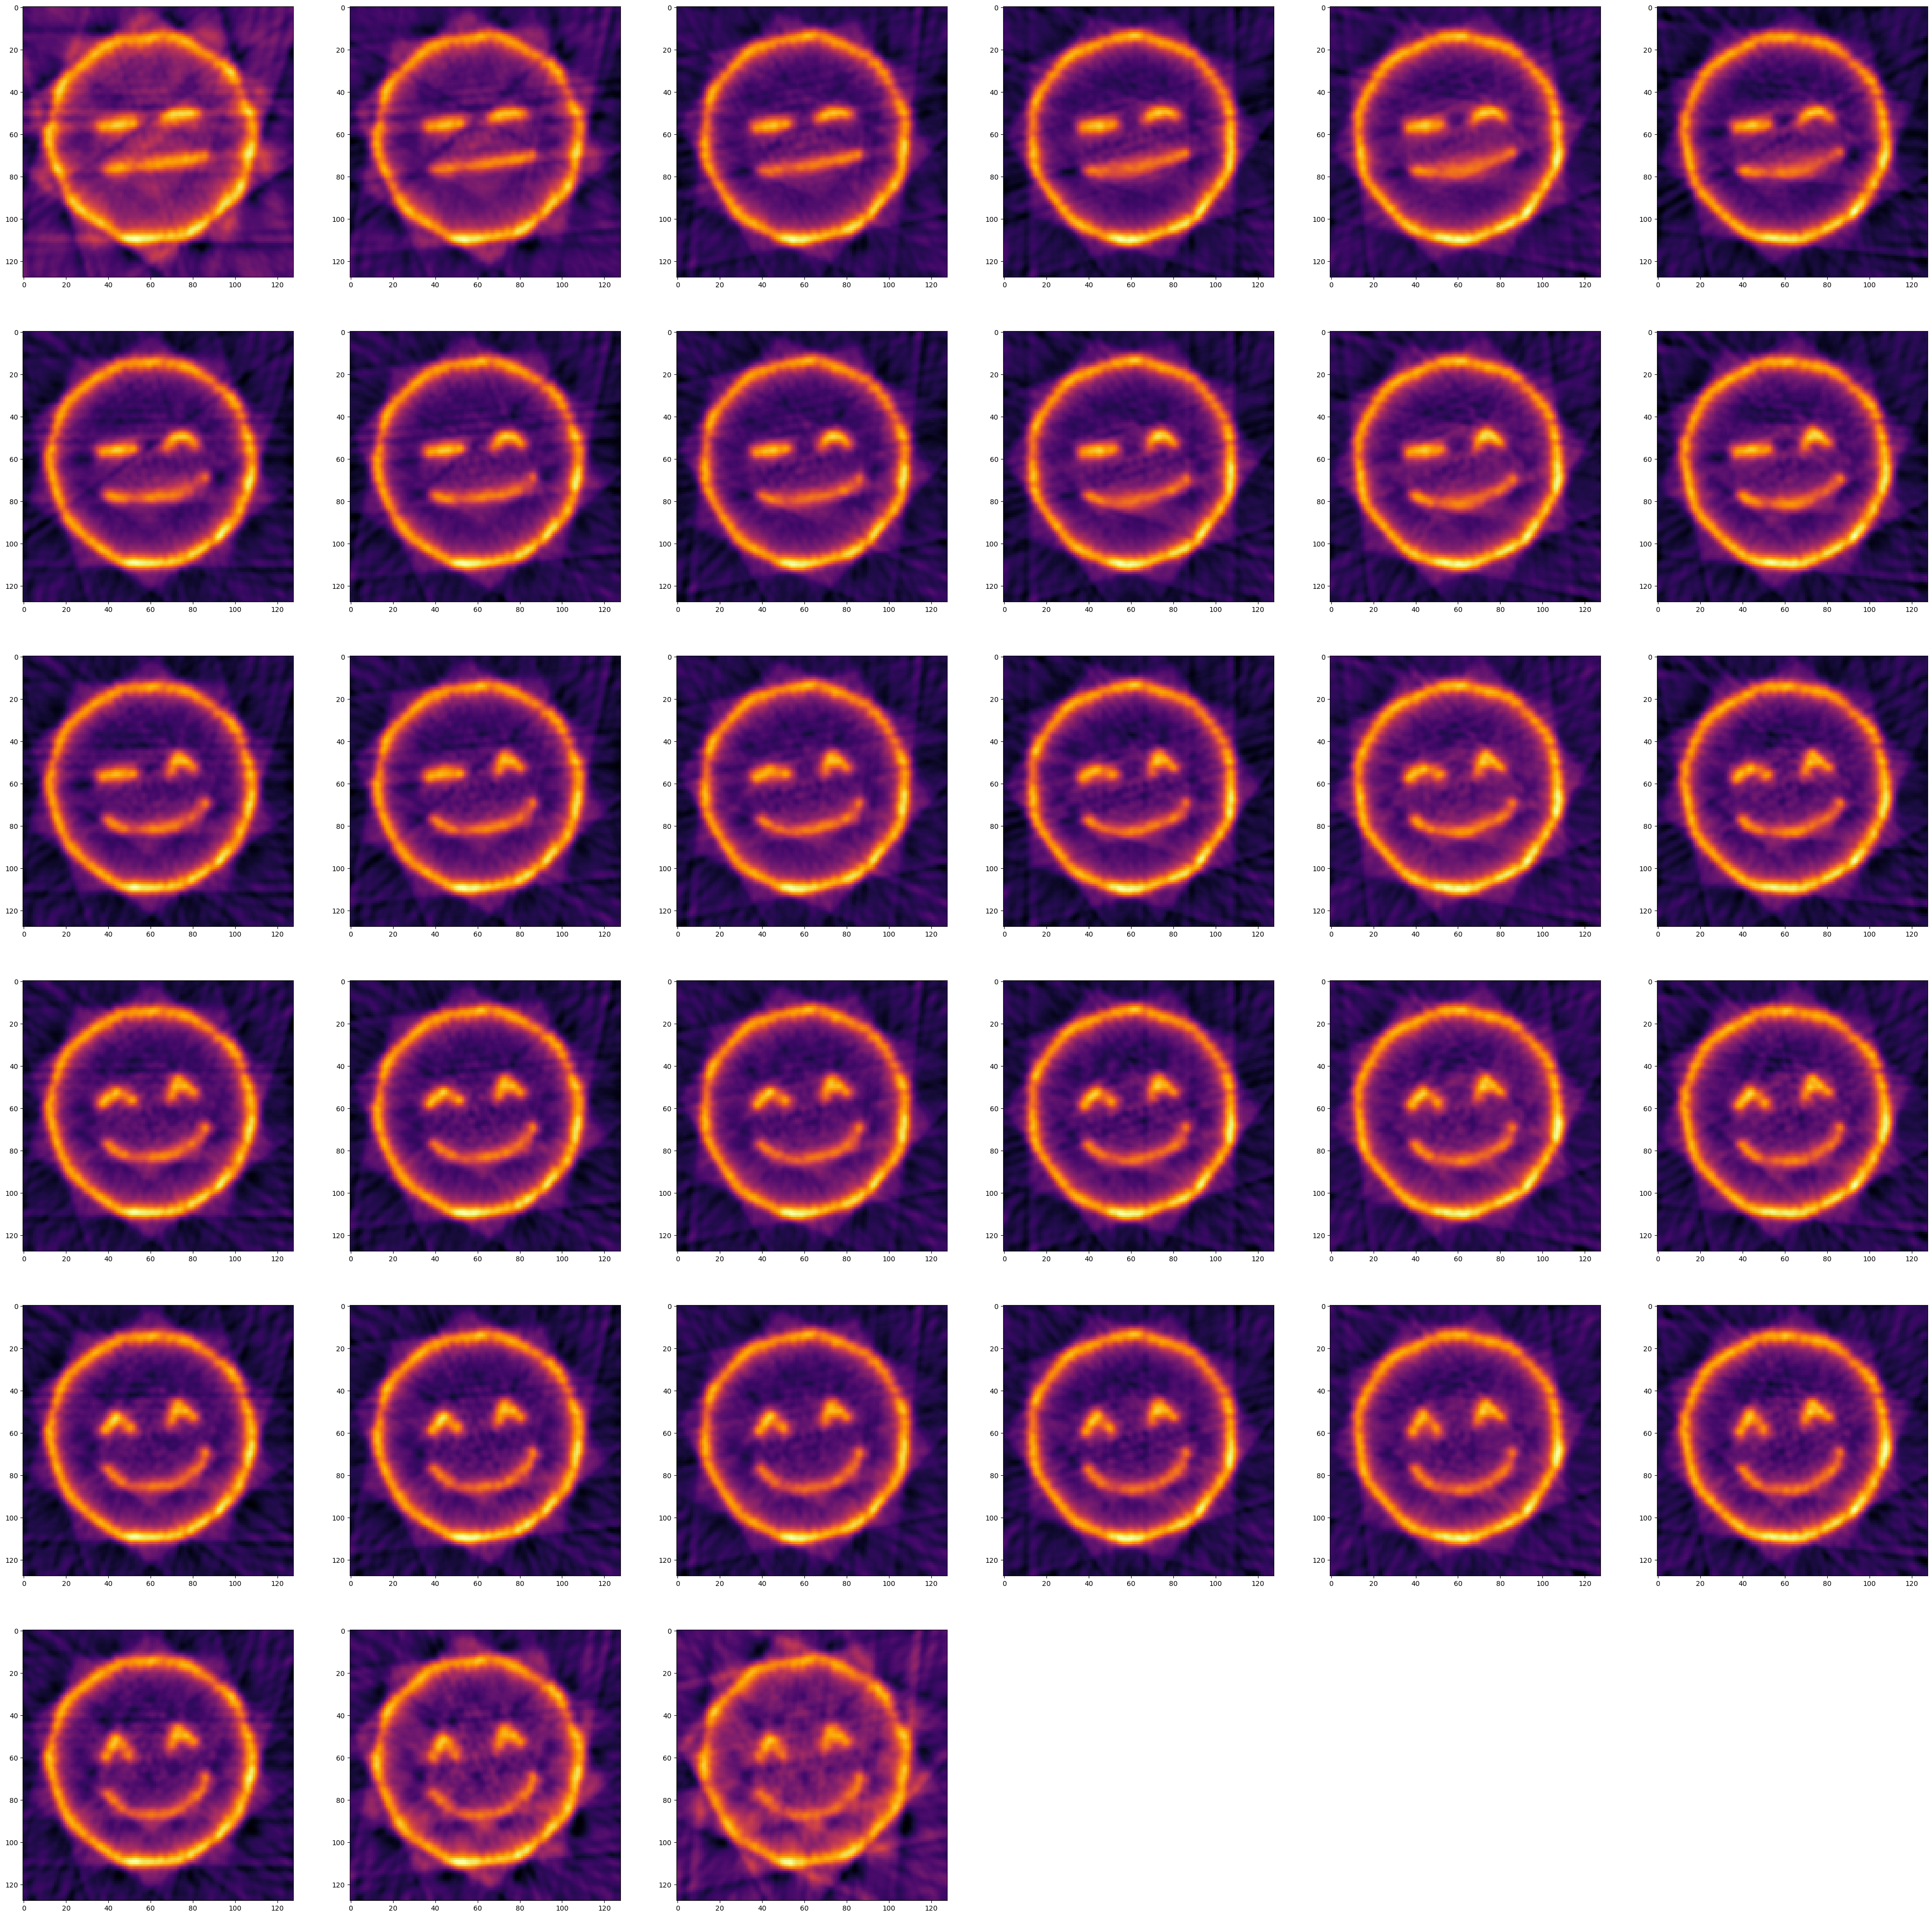

In [8]:
plot_recstructions_series( x_TV_iso , (nx, ny, nt), dynamic = True, testproblem = 'Emoji', geome_x = 1,geome_x_small = 0,  save_imgs= False, save_path='./reconstruction/Emoji')